# Two-Tunable Qubit Hamiltonian: final-unitary SVD-ILC

Model and plumbing live in `two_qubit_model.py`; this notebook sets parameters, builds control pulses and rolls out the dynamics.

**Frame:** rotating at each qubit's idle frequency, RWA.

$$\frac{H(t)}{2\pi} = \sum_i \Big[\Delta_i(t)\, n_i + \tfrac{\alpha_i}{2} b_i^{\dagger 2} b_i^2 + \tfrac{u_{x,i}}{2}(b_i + b_i^\dagger) + \tfrac{u_{y,i}}{2}\, i(b_i^\dagger - b_i)\Big] + J\big(e^{i\delta t} b_1^\dagger b_2 + \text{h.c.}\big)$$

* $\Delta_i(t) = f_i(I(t)) - f_{\text{idle},i}$, with $f_i(\Phi) = f_{\max,i}\sqrt{|\cos(\pi\Phi_i/\Phi_0)|}$ and $\Phi_i = \sum_j M_{ij} I_j$ (crosstalk included).
* $\delta = 2\pi(f_{\text{idle},1} - f_{\text{idle},2})$: the coupling only acts efficiently when flux brings the qubits into resonance.
* `n_levels=2` gives the Pauli model; `n_levels=3` adds leakage.

**Units:** ns, GHz (cyclic), mA, pH. **Controls** are piecewise constant on `N` slices of width `dt`: `I`, `ux`, `uy` each have shape `(2, N)`.

In [1]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt

from two_qubit_model import QubitParams, SystemParams, Controls, TwoQubitModel

## System parameters

In [2]:
params = SystemParams(
    q1=QubitParams(f_max=6.0, alpha=-0.20),   # GHz
    q2=QubitParams(f_max=5.6, alpha=-0.21),
    J=0.010,                                  # GHz (10 MHz)
    M=[[2.00, 0.05],                          # pH, M[i, j]: flux line j -> SQUID i
       [0.05, 2.00]],
    I_idle=[0.0, 0.0],                        # mA (both parked at the sweet spot)
    n_levels=3,
)
model = TwoQubitModel(params)
print("idle frequencies [GHz]:", model.f_idle)
print("idle detuning delta/2pi [GHz]:", model.delta / (2 * np.pi))

idle frequencies [GHz]: [6.  5.6]
idle detuning delta/2pi [GHz]: 0.40000000000000036


## Example control pulses
A Gaussian X π pulse on qubit 1 (|00⟩ → |10⟩), then a flux pulse that tunes qubit 1 into resonance with qubit 2 with a Gaussian-square envelope (5 ns Gaussian edges, flat top $1/(4J)$) (|10⟩ → |01⟩).
Replace these arrays with your optimizer's output.

2438
resonance currents [mA]: [ 0.16904759 -0.00422619] | total duration 48.8 ns


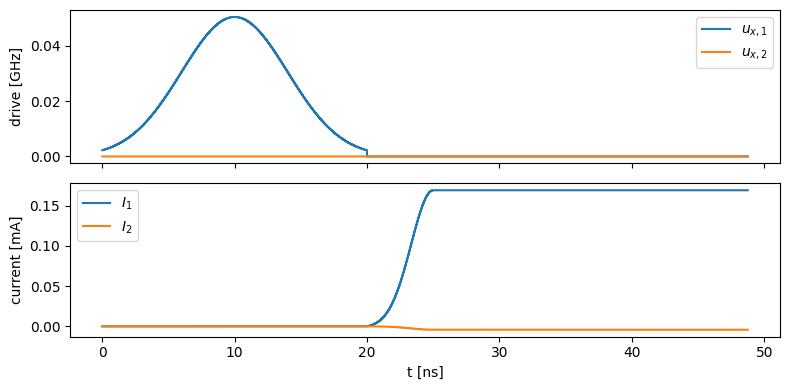

In [3]:
dt = 0.02     
t_edge = 5.0                               # ns, Gaussian rise / fall of the flux pulse                             # ns per slice
t_pi, t_swap = 20.0, 1 / (4 * params.J) - t_edge / 4.0    # ns
N_pi, N_swap, N_edge = round(t_pi / dt), round(t_swap / dt), round(t_edge / dt)
N = N_pi + N_edge + N_swap      # pi pulse | rise | flat top | fall
print(N)
ctrl = Controls.idle(model, N, dt)          # flux at idle, drives off

# Gaussian pi pulse on qubit 1, normalized so the area gives exactly a pi rotation
t = ctrl.t_mid[:N_pi]
g = np.exp(-0.5 * ((t - t_pi / 2) / (t_pi / 5)) ** 2)
ctrl.ux[0, :N_pi] = 0.5 * g / (g.sum() * dt)

# Flux pulse: Gaussian-square from idle to the currents that put qubit 1 at qubit 2's
# idle frequency (crosstalk-corrected). Edges are half-Gaussians with sigma = t_edge/3,
# offset so they start/end exactly at idle; the flat top lasts t_swap.
I_res = model.currents_for_frequencies([model.f_idle[1], model.f_idle[1]])
sigma = t_edge / 3
t_on, t_off = t_pi + t_edge, t_pi + t_edge + t_swap          # flat-top start / end
tm = ctrl.t_mid
g0 = np.exp(-0.5 * (t_edge / sigma) ** 2)                     # Gaussian value at the edge start
edge = lambda x: np.clip((np.exp(-0.5 * (x / sigma) ** 2) - g0) / (1 - g0), 0, 1)
env = np.where(tm < t_pi, 0.0,
      np.where(tm < t_on, edge(tm - t_on),
      np.where(tm <= t_off, 1.0, edge(tm - t_off))))
ctrl.I[:] = model.p.I_idle[:, None] + env[None, :] * (I_res - model.p.I_idle)[:, None]
print("resonance currents [mA]:", I_res, f"| total duration {ctrl.duration:.1f} ns")

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 4))
for i in range(2):
    ax[0].step(ctrl.t_mid, ctrl.ux[i], where="mid", label=f"$u_{{x,{i+1}}}$")
    ax[1].step(ctrl.t_mid, ctrl.I[i], where="mid", label=f"$I_{i+1}$")
ax[0].set_ylabel("drive [GHz]"); ax[1].set_ylabel("current [mA]"); ax[1].set_xlabel("t [ns]")
ax[0].legend(); ax[1].legend(); plt.tight_layout()

## Rollout

{'00': 0.01273, '01': 0.98476, '10': 0.00246, '11': 0.0, 'leak': 5e-05}


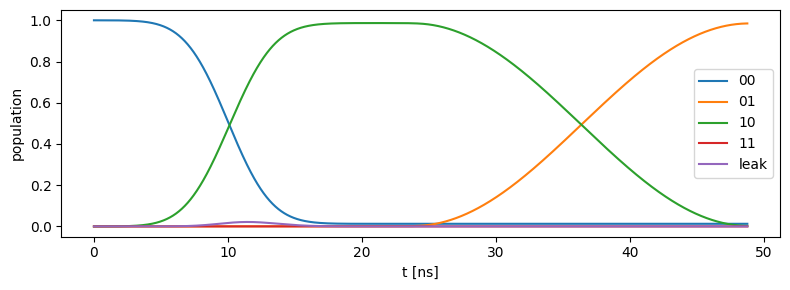

In [4]:
labels = ["00", "01", "10", "11", "leak"]
P = [model.basis(0, 0).proj(), model.basis(0, 1).proj(), model.basis(1, 0).proj(), model.basis(1, 1).proj()]
P.append(qt.qeye(model.dims) - sum(P))

# Closed system. Pass c_ops=model.collapse_ops(T1=(30e3, 30e3), Tphi=(40e3, 40e3)) for decoherence.
res = model.evolve(ctrl, model.basis(0, 0), e_ops=P)

plt.figure(figsize=(8, 3))
for lab, p in zip(labels, res.expect):
    plt.plot(res.times, p, label=lab)
plt.xlabel("t [ns]"); plt.ylabel("population"); plt.legend(); plt.tight_layout()
print({lab: round(float(p[-1]), 5) for lab, p in zip(labels, res.expect)})

# Online "Hardware" Model
Our mutual inductance is SHITTT

{'00': 0.01273, '01': 0.05433, '10': 0.93289, '11': 0.0, 'leak': 5e-05}


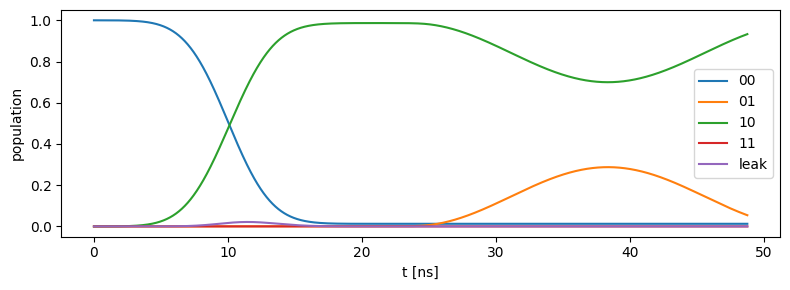

In [5]:
real_params = SystemParams(
    q1=QubitParams(f_max=6.0, alpha=-0.20),   # GHz
    q2=QubitParams(f_max=5.6, alpha=-0.21),
    J=0.010,                                  # GHz (10 MHz)
    M=[[2.00, 0.55],                          # pH, M[i, j]: flux line j -> SQUID i
       [0.55, 2.00]],                         # This is SHITTTTT
    I_idle=[0.0, 0.0],                        # mA (both parked at the sweet spot)
    n_levels=3,
)
real_model = TwoQubitModel(real_params)

labels = ["00", "01", "10", "11", "leak"]
P = [real_model.basis(0, 0).proj(), real_model.basis(0, 1).proj(), real_model.basis(1, 0).proj(), real_model.basis(1, 1).proj()]
P.append(qt.qeye(real_model.dims) - sum(P))


# Closed system. Pass c_ops=real_model.collapse_ops(T1=(30e3, 30e3), Tphi=(40e3, 40e3)) for decoherence.
real_res = real_model.evolve(ctrl, real_model.basis(0, 0), e_ops=P)

plt.figure(figsize=(8, 3))
for lab, p in zip(labels, real_res.expect):
    plt.plot(real_res.times, p, label=lab)
plt.xlabel("t [ns]"); plt.ylabel("population"); plt.legend(); plt.tight_layout()
print({lab: round(float(p[-1]), 5) for lab, p in zip(labels, real_res.expect)})

## SVD-ILC setup: final-unitary Jacobian
Nominal pulse `ctrl` in the offline `model` (crosstalk 0.05); "hardware" = `real_model` (crosstalk 0.55) with shot noise.

The initial error basis below comes from the SVD of the **final-unitary Jacobian** at the nominal pulse,
$J_U = \partial\,\mathrm{vec}(U_T[:,\text{comp}])/\partial a \approx U_r\Sigma_rV_r^\top$ (real-stacked $[\mathrm{Re};\mathrm{Im}]$).
Each left-singular vector $u_i$ is an error direction of the end map, shown as the $9\times4$ matrix $\delta U_T$ it represents
(rows: output level, columns: computational input); the right-singular vectors $v_i$ are the matching pulse modes.

J_U (real-stacked): (72, 14628)  top singular values: [10.43   3.865  1.601  0.498  0.486  0.29 ]


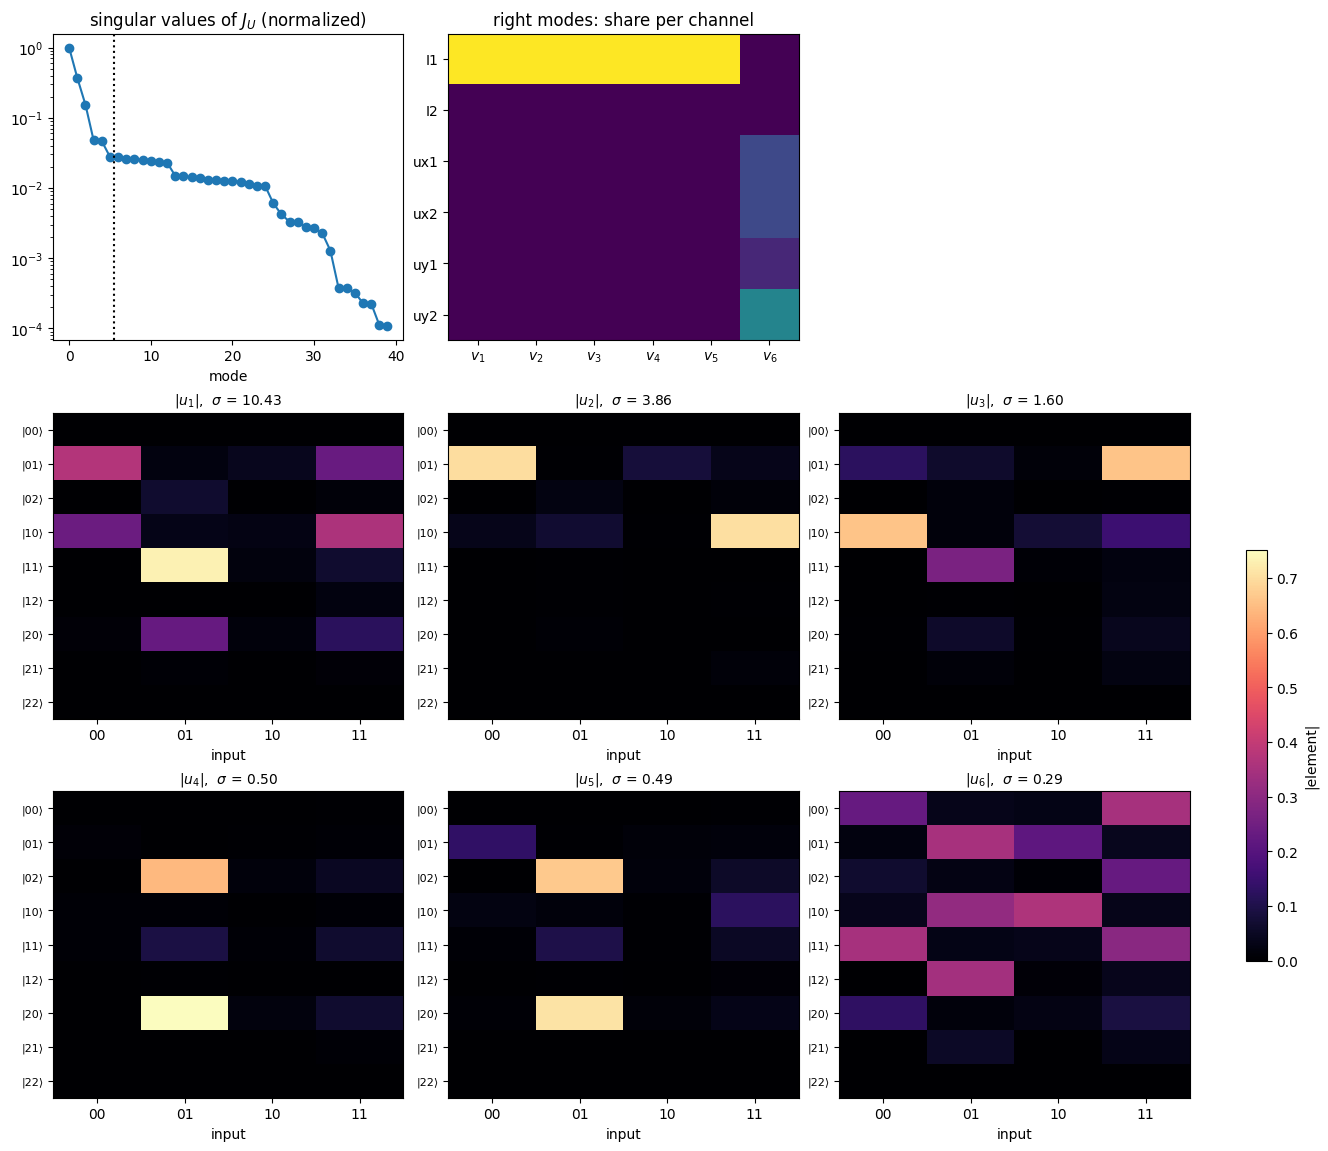

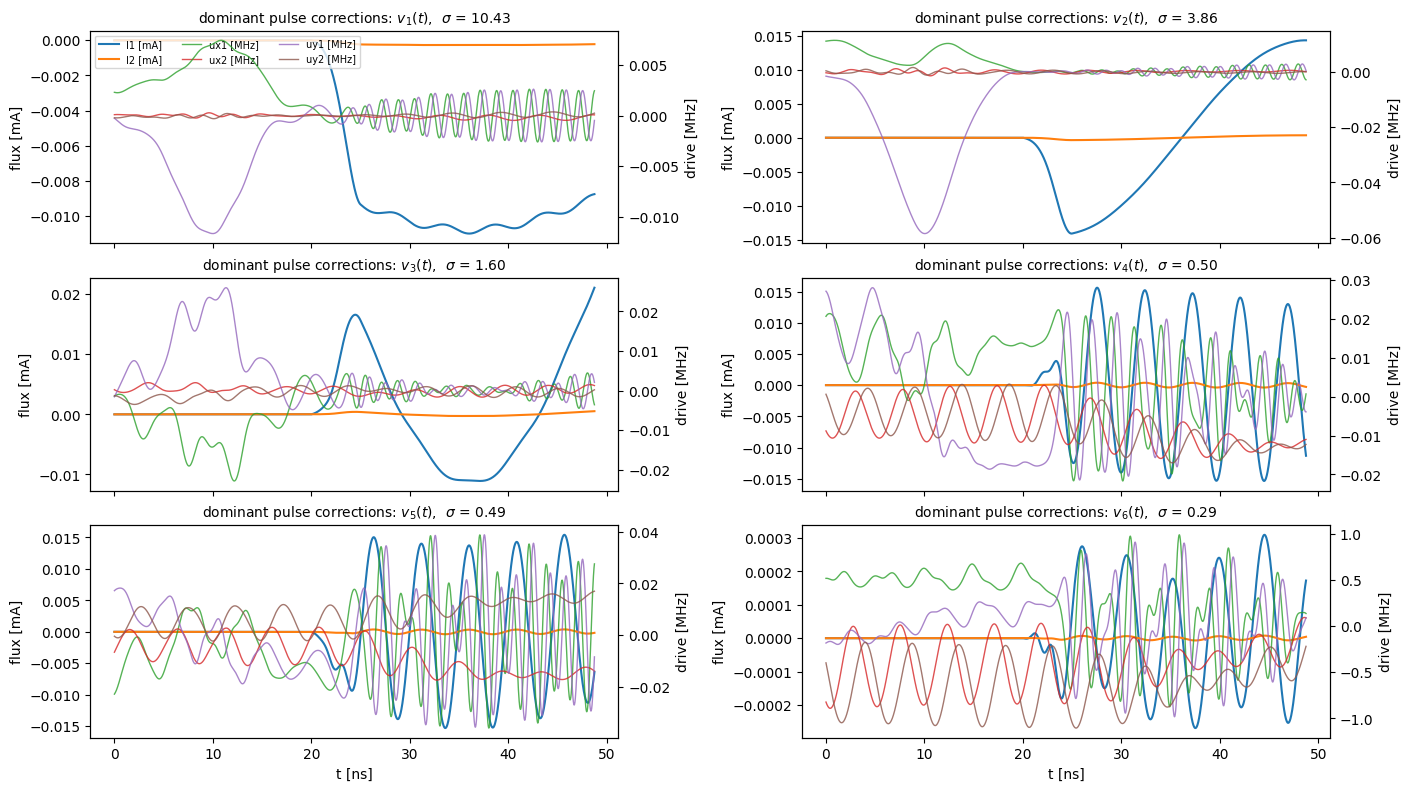

In [12]:
from ilc import SVDILC, CHANNELS, embedded_paulis, product_state, tracking_fidelity

USE_DRIVES = True                                                 # False: ILC corrects flux (I1, I2) only
ACTIVE = CHANNELS if USE_DRIVES else ["I1", "I2"]

SVD_RANK = 6                                                      # modes shown below

paulis = embedded_paulis(model)                                   # XI, IX, YI, IY, ZI, IZ
states = [product_state(model, "0", "0"), product_state(model, "+", "+")]
checkpoints = np.unique(np.append(np.arange(25, ctrl.n_slices + 1, 25), ctrl.n_slices))  # every 0.5 ns + final time
ALWAYS_MEASURE_FINAL = True                                       # final time is measured on every ILC step
REQUIRED = [len(checkpoints) - 1] if ALWAYS_MEASURE_FINAL else None
SHOTS = 1000

ilc = SVDILC(model, states, list(paulis.values()), checkpoints, active_channels=ACTIVE)

# Initial SVD of the final-unitary Jacobian J_U = dU_T[:, comp]/da at the nominal pulse (offline model),
# real-stacked [Re; Im] exactly as in plan_final_unitary
J_U, U_T_cols = ilc.compute_unitary_jacobian(ctrl)               # complex (D*4, 6N), U_T[:, comp]
J_Ur = np.vstack([J_U.real, J_U.imag])
UU, SU, VUt = np.linalg.svd(J_Ur, full_matrices=False)
print("J_U (real-stacked):", J_Ur.shape, " top singular values:", np.round(SU[:SVD_RANK], 3))

# Left-singular error modes u_i -> D x 4 complex matrices (rows: output level, cols: computational input)
n_lev, D = model.p.n_levels, J_U.shape[0] // 4
out_labels = [f"|{i}{j}⟩" for i in range(n_lev) for j in range(n_lev)]
in_labels = ["00", "01", "10", "11"]
E = (UU[:D * 4, :SVD_RANK] + 1j * UU[D * 4:, :SVD_RANK]).T.reshape(SVD_RANK, D, 4)

ncol = 3
nrow = 1 + int(np.ceil(SVD_RANK / ncol))
fig, ax = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.8 * nrow), constrained_layout=True)
ax = np.atleast_2d(ax)
ax[0, 0].semilogy(SU[:40] / SU[0], "o-"); ax[0, 0].axvline(SVD_RANK - 0.5, color="k", ls=":")
ax[0, 0].set_title("singular values of $J_U$ (normalized)"); ax[0, 0].set_xlabel("mode")
# pulse-mode content per channel (right-singular vectors), for reference
share = (VUt[:SVD_RANK].reshape(SVD_RANK, 6, -1) ** 2).sum(axis=2)
ax[0, 1].imshow(share.T, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax[0, 1].set_yticks(range(6)); ax[0, 1].set_yticklabels(CHANNELS); ax[0, 1].set_xticks(range(SVD_RANK))
ax[0, 1].set_xticklabels([f"$v_{i+1}$" for i in range(SVD_RANK)]); ax[0, 1].set_title("right modes: share per channel")
ax[0, 2].axis("off")
vmax = np.abs(E).max()
for i in range(SVD_RANK):
    a = ax[1 + i // ncol, i % ncol]
    im = a.imshow(np.abs(E[i]), cmap="magma", vmin=0, vmax=vmax, aspect="auto")
    a.set_xticks(range(4)); a.set_xticklabels(in_labels); a.set_yticks(range(D)); a.set_yticklabels(out_labels, fontsize=8)
    a.set_xlabel("input"); a.set_title(f"$|u_{i+1}|$,  $\\sigma$ = {SU[i]:.2f}", fontsize=10)
for j in range(SVD_RANK, (nrow - 1) * ncol):
    ax[1 + j // ncol, j % ncol].axis("off")
fig.colorbar(im, ax=ax[1:, :].ravel().tolist(), shrink=0.6, label="|element|")


# Dominant pulse corrections: right-singular vectors v_i(t) of J_U in physical units
modes_t = VUt[:SVD_RANK].reshape(SVD_RANK, 6, -1) * ilc.scales[None, :, None]
fig2, ax2 = plt.subplots(int(np.ceil(SVD_RANK / 2)), 2, figsize=(14, 2.6 * int(np.ceil(SVD_RANK / 2))),
                         sharex=True, constrained_layout=True)
ax2 = np.atleast_2d(ax2)
for i in range(SVD_RANK):
    a = ax2[i // 2, i % 2]
    for k, ch in enumerate(CHANNELS[:2]):
        a.plot(ctrl.t_mid, modes_t[i, k], color=f"C{k}", label=f"{ch} [mA]")
    b = a.twinx()
    for k, ch in enumerate(CHANNELS[2:], start=2):
        b.plot(ctrl.t_mid, modes_t[i, k] * 1e3, color=f"C{k}", lw=1, alpha=0.8, label=f"{ch} [MHz]")
    a.set_title(f"dominant pulse corrections: $v_{i+1}(t)$,  $\\sigma$ = {SU[i]:.2f}", fontsize=10)
    a.set_ylabel("flux [mA]"); b.set_ylabel("drive [MHz]")
    if i == 0:
        h1, l1 = a.get_legend_handles_labels(); h2, l2 = b.get_legend_handles_labels()
        a.legend(h1 + h2, l1 + l2, fontsize=7, ncol=3, loc="upper left")
for j in range(SVD_RANK, ax2.size):
    ax2[j // 2, j % 2].axis("off")
for a in ax2[-1]:
    a.set_xlabel("t [ns]")

## Final-unitary SVD-ILC
The goal is the end map, not the offline trajectory. Each hardware iteration:
1. **Measure** the hardware at `N_TIMES` checkpoints (shot noise; the final time is always included) and **fit** the parameters `FIT` by Gauss-Newton on all data so far.
2. **Plan** on the fitted model, starting from the nominal pulse each time (`WARM_START = False`), so corrections planned on earlier, wrong models are not carried over: Gauss-Newton on the final-unitary error
   $e = \mathrm{vec}\big(e^{-i\varphi}U_T[:,\text{comp}] - U_{\text{target}}[:,\text{comp}]\big)$ (all 9 output levels, so leakage counts),
   with a rank-`R_RANK` SVD of the analytic Jacobian $J_U = \partial U_T/\partial a = U_r\Sigma_rV_r^\top$:
   $c = -(\Sigma_r U_r^\top e + \mu V_r^\top(a-a_0)) / (\Sigma_r^2 + \mu + \lambda^2)$, $\Delta a = V_r c$, step halved until the model fidelity improves.
   Intermediate times are unconstrained; $\mu$ = `ANCHOR` keeps the pulse near the nominal one, where the model has been tested.
3. **Choose the next measurement times** for Fisher information about $\theta$ (not about the trajectory).

The target is the nominal pulse's map in the offline model, `U_ref`; replace `U_TARGET` with any gate (e.g. a CZ) to retarget.

iter 0: hardware final-map fidelity 0.03675  theta [0.05 0.05]
   fit chi2/meas 0.95 (grid scan) | planned model fidelity 0.03605 -> 0.99929 in 20 steps
iter 1: hardware final-map fidelity 0.30526  theta [-0.4506  0.5571]
   fit chi2/meas 0.94 (grid scan) | planned model fidelity 0.30527 -> 0.96211 in 15 steps
iter 2: hardware final-map fidelity 0.96207  theta [0.5499 0.5487]
   fit chi2/meas 1.00 | planned model fidelity 0.96204 -> 0.96204 in 0 steps
iter 3: hardware final-map fidelity 0.96207  theta [0.5503 0.5469]
   fit chi2/meas 0.95 | planned model fidelity 0.96208 -> 0.96208 in 0 steps
iter 4: hardware final-map fidelity 0.96207  theta [0.5501 0.5481]
   fit chi2/meas 0.91 | planned model fidelity 0.96202 -> 0.96202 in 0 steps
iter 5: hardware final-map fidelity 0.96207  theta [0.5503 0.5486]
   fit chi2/meas 0.92 | planned model fidelity 0.96199 -> 0.96199 in 0 steps
iter 6: hardware final-map fidelity 0.96207  theta [0.5504 0.549 ]


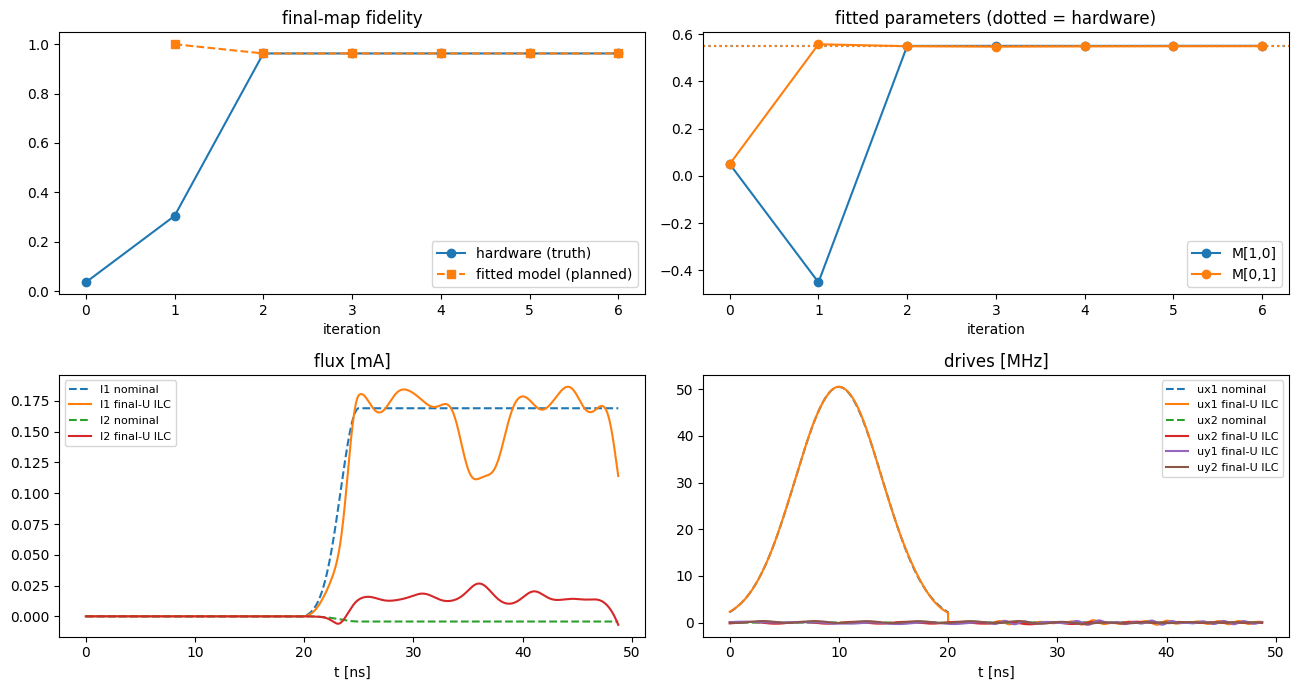

In [7]:
from ilc import run_final_unitary_ilc, get_param

_, U_ref = ilc.simulate_rollout(ctrl)          # nominal map in the offline model
U_TARGET = U_ref
SUBSTEPS = 4                                    # hardware integration sub-slices

FIT = ["M[1,0]", "M[0,1]"]                      # parameters to fit (you choose)
PRIOR_STD = [1.0] * len(FIT)
SCAN = {n: (get_param(params, n) - 1.0, get_param(params, n) + 1.5) for n in FIT}

R_RANK = 8                                      # SVD modes of J_U per planning step
N_PLAN_STEPS = 20                               # Gauss-Newton steps on the fitted model per hardware iteration
ANCHOR = 1e-2                                   # pull toward the nominal pulse (0 = pure fidelity)
N_TIMES = 4                                     # hardware measurement times per iteration
WARM_START = False                              # False: re-plan from the nominal pulse on each fitted model
N_ITER_U = 6

ilc_u = SVDILC(model, states, list(paulis.values()), checkpoints, active_channels=ACTIVE)
ctrl_final, log_u = run_final_unitary_ilc(
    ilc_u, ctrl, U_TARGET, params, real_model, FIT, scan=SCAN, prior_std=PRIOR_STD,
    n_iter=N_ITER_U, r_rank=R_RANK, n_plan_steps=N_PLAN_STEPS, anchor=ANCHOR,
    n_times=N_TIMES, required_times=REQUIRED, shots=SHOTS, substeps=SUBSTEPS, warm_start=WARM_START)

th = np.array(log_u["theta"])
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
ax[0, 0].plot(log_u["F_hw"], "o-", label="hardware (truth)")
ax[0, 0].plot(range(1, len(log_u["F_model"]) + 1), log_u["F_model"], "s--", label="fitted model (planned)")
ax[0, 0].set_title("final-map fidelity"); ax[0, 0].set_xlabel("iteration"); ax[0, 0].legend()
for i, n in enumerate(FIT):
    ax[0, 1].plot(th[:, i], "o-", color=f"C{i}", label=n)
    ax[0, 1].axhline(get_param(real_params, n), ls=":", color=f"C{i}")
ax[0, 1].set_title("fitted parameters (dotted = hardware)"); ax[0, 1].set_xlabel("iteration"); ax[0, 1].legend()
for i, lab in enumerate(["I1", "I2"]):
    ax[1, 0].plot(ctrl.t_mid, ctrl.I[i], "--", label=f"{lab} nominal")
    ax[1, 0].plot(ctrl.t_mid, ctrl_final.I[i], label=f"{lab} final-U ILC")
ax[1, 0].set_title("flux [mA]"); ax[1, 0].set_xlabel("t [ns]"); ax[1, 0].legend(fontsize=8)
for i, lab in enumerate(["ux1", "ux2"]):
    ax[1, 1].plot(ctrl.t_mid, ctrl.ux[i] * 1e3, "--", label=f"{lab} nominal")
    ax[1, 1].plot(ctrl.t_mid, ctrl_final.ux[i] * 1e3, label=f"{lab} final-U ILC")
for i, lab in enumerate(["uy1", "uy2"]):
    ax[1, 1].plot(ctrl.t_mid, ctrl_final.uy[i] * 1e3, label=f"{lab} final-U ILC")
ax[1, 1].set_title("drives [MHz]"); ax[1, 1].set_xlabel("t [ns]"); ax[1, 1].legend(fontsize=8)
plt.tight_layout()

### Comparison with the analytical crosstalk inverse
$I_{\text{fix}} = \hat M^{-1} M_{\text{offline}} I_{\text{nom}}$ with the fitted $\hat M$ and with the true hardware $M$, scored on the hardware model (final-map fidelity vs `U_TARGET`).

In [8]:
from ilc import with_parameters

def crosstalk_inverse(ctrl_nom, M_offline, M_new):
    I_fix = np.linalg.solve(M_new, M_offline @ ctrl_nom.I)
    return Controls(ctrl_nom.dt, I_fix, ctrl_nom.ux.copy(), ctrl_nom.uy.copy())

M_fit = with_parameters(params, FIT, log_u["theta"][-1]).p.M
comp = model.computational_indices()
T_cols = U_TARGET.full()[:, comp]
candidates = {
    "nominal pulse":        ctrl,
    "final-U SVD-ILC":      ctrl_final,
    "analytic (fitted M)":  crosstalk_inverse(ctrl, params.M, M_fit),
    "analytic (true M)":    crosstalk_inverse(ctrl, params.M, real_params.M),
}
print(f"{'pulse':22s} {'hardware final-map fidelity':>28s}")
for name, c in candidates.items():
    print(f"{name:22s} {ilc_u.final_fidelity(c, T_cols, model=real_model):28.5f}")

pulse                   hardware final-map fidelity
nominal pulse                               0.03675
final-U SVD-ILC                             0.96207
analytic (fitted M)                         0.99994
analytic (true M)                           1.00000


### Populations under the final-unitary ILC pulse
Colour = state, line style = run. Intermediate populations may differ from the target trajectory; only the end map is targeted.

target: nominal pulse, offline model     final: 00 0.0127  01 0.9848  10 0.0025  11 0.0000  leak 0.0001
nominal pulse, hardware                  final: 00 0.0127  01 0.0543  10 0.9329  11 0.0000  leak 0.0001
final-U SVD-ILC pulse, hardware          final: 00 0.0091  01 0.8932  10 0.0973  11 0.0002  leak 0.0002


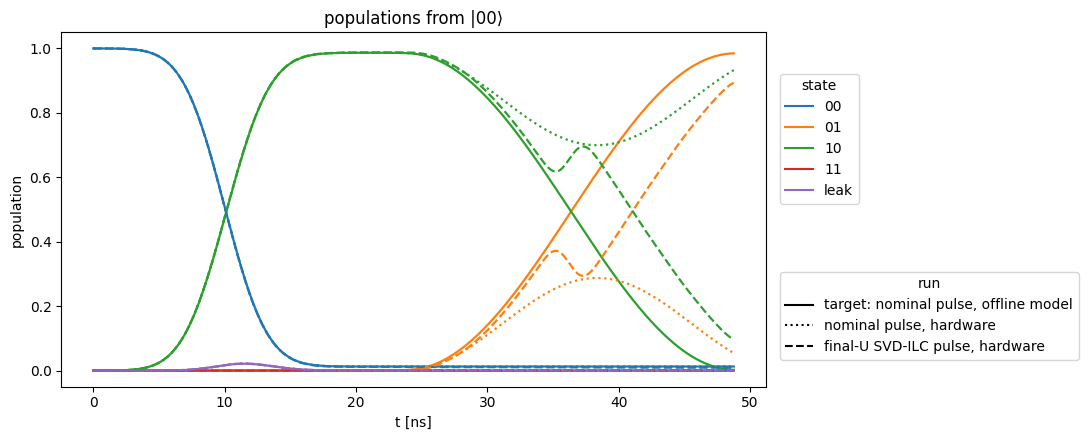

In [10]:
from matplotlib.lines import Line2D

PSI0_LABELS = ("0", "0")                      # initial product state, e.g. ("+", "+")
psi0 = product_state(model, *PSI0_LABELS)
pop_labels = ["00", "01", "10", "11", "leak"]
def pop_ops(m):
    P = [m.basis(0, 0).proj(), m.basis(0, 1).proj(), m.basis(1, 0).proj(), m.basis(1, 1).proj()]
    return P + [qt.qeye(m.dims) - sum(P)]

runs = [("target: nominal pulse, offline model", model, ctrl, "-"),
        ("nominal pulse, hardware", real_model, ctrl, ":"),
        ("final-U SVD-ILC pulse, hardware", real_model, ctrl_final, "--")]
fig, ax = plt.subplots(figsize=(11, 4.5))
for title, m, c, ls in runs:
    r = m.evolve(c, psi0, e_ops=pop_ops(m))
    for k, pop in enumerate(r.expect):
        ax.plot(r.times, pop, ls=ls, color=f"C{k}", lw=1.6)
    print(f"{title:40s} final: " + "  ".join(f"{l} {p[-1]:.4f}" for l, p in zip(pop_labels, r.expect)))
leg = ax.legend([Line2D([], [], color=f"C{k}") for k in range(5)], pop_labels, title="state",
                loc="center left", bbox_to_anchor=(1.01, 0.7))
ax.add_artist(leg)
ax.legend([Line2D([], [], color="k", ls=ls) for *_, ls in runs], [t for t, *_ in runs], title="run",
          loc="center left", bbox_to_anchor=(1.01, 0.2))
ax.set_xlabel("t [ns]"); ax.set_ylabel("population"); ax.set_title(f"populations from |{''.join(PSI0_LABELS)}⟩")
plt.tight_layout()